# ML Lab 1 – Exploring the Ames Housing dataset

In this notebook we take a first look at the Ames Housing data with pandas: what's in it, what's missing, what looks weird, and which features seem to be connected. We check the data quality (missing values, outliers), look at distributions and relationships with different kinds of plots, and think about which features we'd drop, which new ones we could build, and what outside data could help.

## What this notebook does

We want to understand the Ames Housing data (2930 houses, 82 features) before we use it in the next labs. The notebook goes through these steps:

1. **Load the data:** read the CSV with pandas and check that it looks right.
2. **Look at the features:** which columns are numbers, which are categories, and which ones are tricky.
3. **Clean the data (preprocessing):** deal with missing values and outliers, decide which columns we'd drop, and think of new ones we could create. We also write down what outside data could help.
4. **Plots:** at least 10 different plots (histogram, scatter, box, violin, heatmap, ...) to see how values are spread and how features are connected, with a short explanation under each.
5. **Bonus, linear regression:** pick two pairs of features that look linearly related, fit a line, and compare real vs. predicted values.

Each part has a short text explaining what we did and what we found.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Loading the data

`AmesHousing.csv` is **tab-separated**, not comma-separated, so we need `sep="\t"`. Without it pandas reads each row as one giant column (we got `shape = (2930, 1)` at first, which was the hint that something was off).

Result: **2930 rows (houses)** and **82 columns (features)**.

In [3]:
housing = pd.read_csv("AmesHousing.csv", sep="\t")
print(housing.shape)
housing.head()

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

Quick takeaways from `info()`:
- 82 columns: 28 `int64`, 11 `float64`, 43 `str`.
- Some columns have fewer than 2930 non-null values (e.g. `Lot Frontage` has 2440, `Alley` only 198), so there's missing data. We look at that in section 3.

In [5]:
num_cols = housing.select_dtypes(include="number").columns.tolist()
cat_cols = housing.select_dtypes(exclude="number").columns.tolist()
print(len(num_cols), "numeric,", len(cat_cols), "categorical")
print(num_cols)

39 numeric, 43 categorical
['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'SalePrice']


## 2. Looking at features

First we split the columns into numeric and categorical. pandas does this by data type, but the data type doesn't always match what a column *means*, so we also checked the description file (`AmesExplanations.txt`), which labels every feature as nominal, ordinal, discrete or continuous.

In [6]:
# by meaning, based on AmesExplanations.txt
identifiers = ["Order", "PID"]

numeric_continuous = ["Lot Frontage", "Lot Area", "Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2",
                      "Bsmt Unf SF", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF", "Low Qual Fin SF",
                      "Gr Liv Area", "Garage Area", "Wood Deck SF", "Open Porch SF", "Enclosed Porch",
                      "3Ssn Porch", "Screen Porch", "Pool Area", "Misc Val", "SalePrice"]

numeric_discrete = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Mo Sold", "Yr Sold",
                    "Bsmt Full Bath", "Bsmt Half Bath", "Full Bath", "Half Bath", "Bedroom AbvGr",
                    "Kitchen AbvGr", "TotRms AbvGrd", "Fireplaces", "Garage Cars"]

categorical_nominal = ["MS SubClass", "MS Zoning", "Street", "Alley", "Land Contour", "Lot Config",
                       "Neighborhood", "Condition 1", "Condition 2", "Bldg Type", "House Style",
                       "Roof Style", "Roof Matl", "Exterior 1st", "Exterior 2nd", "Mas Vnr Type",
                       "Foundation", "Heating", "Central Air", "Garage Type", "Misc Feature",
                       "Sale Type", "Sale Condition"]

categorical_ordinal = ["Overall Qual", "Overall Cond", "Lot Shape", "Utilities", "Land Slope",
                       "Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
                       "BsmtFin Type 1", "BsmtFin Type 2", "Heating QC", "Electrical", "Kitchen Qual",
                       "Functional", "Fireplace Qu", "Garage Finish", "Garage Qual", "Garage Cond",
                       "Paved Drive", "Pool QC", "Fence"]

groups = {"identifiers": identifiers, "numeric continuous": numeric_continuous,
          "numeric discrete": numeric_discrete, "categorical nominal": categorical_nominal,
          "categorical ordinal": categorical_ordinal}

all_listed = sum(groups.values(), [])
print("listed:", len(all_listed), "| unique:", len(set(all_listed)), "| in data:", housing.shape[1])
print("missing from lists:", set(housing.columns) - set(all_listed))
print("not in data:", set(all_listed) - set(housing.columns))
for name, cols in groups.items():
    print(f"{name}: {len(cols)}")

listed: 82 | unique: 82 | in data: 82
missing from lists: set()
not in data: set()
identifiers: 2
numeric continuous: 20
numeric discrete: 14
categorical nominal: 23
categorical ordinal: 23


**Result:** pandas finds 39 numeric and 43 categorical columns. By meaning it looks a bit different:
- **Identifiers (2):** `Order` and `PID` are just IDs, even though they are numbers.
- **Numeric, continuous (20):** sizes and areas in square feet, `Lot Frontage`, `Misc Val` and `SalePrice`.
- **Numeric, discrete (14):** counts (bathrooms, bedrooms, fireplaces, garage cars) and years/months.
- **Categorical, nominal (23):** no order, e.g. `Neighborhood`, `House Style`, `Foundation`. This includes `MS SubClass`, which is stored as a number but is really a code for the dwelling type.
- **Categorical, ordinal (23):** have a natural order, e.g. the quality ratings (Ex > Gd > TA > Fa > Po). Two of them, `Overall Qual` and `Overall Cond` (1–10), are stored as numbers.

So 5 columns are numbers by data type but not really numeric in meaning (`Order`, `PID`, `MS SubClass`, `Overall Qual`, `Overall Cond`).

In [7]:
corr = housing[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
upper.stack().sort_values(ascending=False).head(7)

Order          Yr Sold          0.975993
Garage Cars    Garage Area      0.889676
Year Built     Garage Yr Blt    0.834849
Gr Liv Area    TotRms AbvGrd    0.807772
Total Bsmt SF  1st Flr SF       0.800720
Overall Qual   SalePrice        0.799262
Gr Liv Area    SalePrice        0.706780
dtype: float64

In [8]:
print("Garage built same year as house:", (housing["Garage Yr Blt"] == housing["Year Built"]).mean().round(2))
print("Never remodeled:", (housing["Year Remod/Add"] == housing["Year Built"]).mean().round(2))

Garage built same year as house: 0.76
Never remodeled: 0.54


### Connections between features

We checked the correlations between all numeric columns and looked at the strongest pairs:

- **Garage size:** `Garage Cars` and `Garage Area` (r = 0.89) measure the same thing in two ways, number of cars and square feet.
- **Garage and house age:** `Year Built` and `Garage Yr Blt` (r = 0.83). For 76% of the houses the garage was built in the same year as the house.
- **House size and rooms:** `Gr Liv Area` goes with `TotRms AbvGrd` (r = 0.81), and `TotRms AbvGrd` with `Bedroom AbvGr` (r = 0.67). Bigger houses have more rooms. `2nd Flr SF` is part of `Gr Liv Area` (r = 0.66).
- **Basement and first floor:** `Total Bsmt SF` and `1st Flr SF` (r = 0.80). This makes sense, because a basement usually sits under the first floor and has about the same size.
- **Remodeling:** `Year Remod/Add` and `Garage Yr Blt` (r = 0.65). 54% of the houses were never remodeled, since their remodel year equals the build year.
- **Price:** `SalePrice` goes with `Overall Qual` (r = 0.80) and with `Gr Liv Area` (r = 0.71). Better quality and more living space mean a higher price.
- **Order and sale year:** `Order` and `Yr Sold` have r = −0.98. That's odd for a column that is just a row number. It turns out the rows are sorted by sale year from the latest to the earliest, so the row number carries no meaning about the house itself. This is another reason to drop `Order`.


In [9]:
print("Raw value:", housing["Order"].corr(housing["Yr Sold"]))

Raw value: -0.9759929037175532



These are only correlations between numeric columns, and they only measure straight-line relationships. Connections between categorical columns (e.g. `Neighborhood` and `MS Zoning`) are not covered here.

## 3. Preprocessing 

In [10]:
clean_df = housing.copy()   # housing stays raw, clean_df gets cleaned

In [11]:
missing = housing.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(housing) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
Pool QC,2917,99.6
Misc Feature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
Mas Vnr Type,1775,60.6
Fireplace Qu,1422,48.5
Lot Frontage,490,16.7
Garage Qual,159,5.4
Garage Cond,159,5.4
Garage Yr Blt,159,5.4


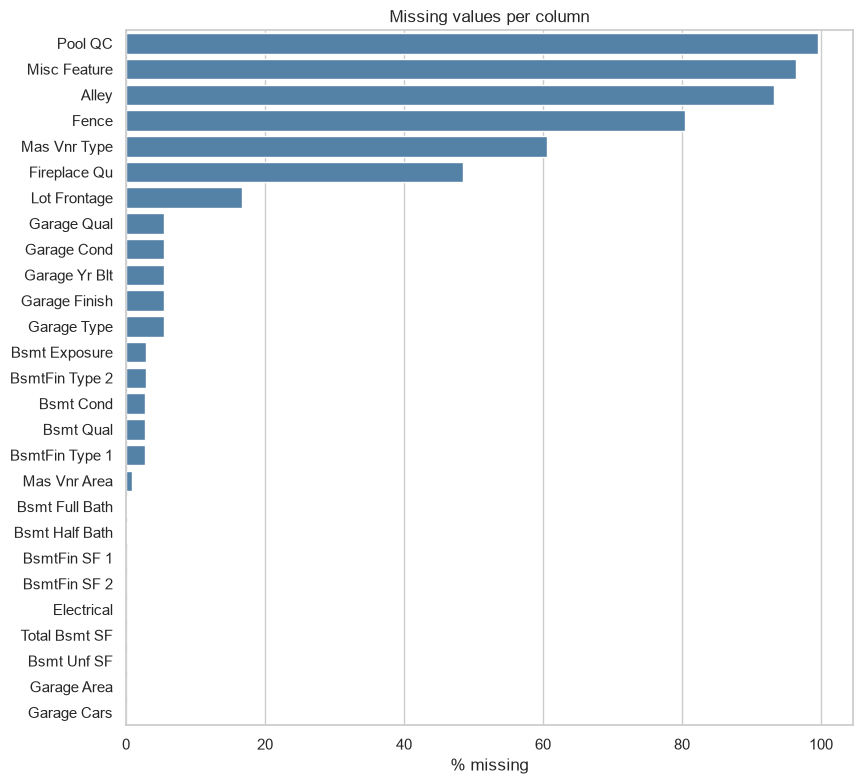

In [12]:
plt.figure(figsize=(9, 8))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.tight_layout()
plt.ylabel("")
plt.show()

### 3.1 Missing values

27 columns have missing values. The biggest are `Pool QC` (99.6%), `Misc Feature` (96.4%), `Alley` (93.2%) and `Fence` (80.5%). The garage columns all miss the same 159 rows, and the basement columns about 80.

But NaN doesn't always mean "data lost". The description file says `NA` means "no pool / no alley / no garage / ...". We tested this: for all 11 columns we checked, 100% of the houses without the feature (e.g. `Pool Area = 0`) have NaN there. So NaN mostly means "this house doesn't have it", and dropping `Pool QC` for being 99.6% empty would throw away information.

`Mas Vnr Type` has 1775 NaN and no "None" category at all. pandas reads the string "None" as NaN, and 1748 houses have `Mas Vnr Area = 0`, so these are houses without veneer. Only 23 rows are really missing.

Real missing data: `Lot Frontage` (490 rows, 16.7%), 23 veneer rows, `Electrical` (1 row), and a few houses (about 10) that have a basement or garage but a missing label.

### 3.2 How we fill them

- **NaN = feature doesn't exist:** text columns get `"None"`, numeric ones (areas, counts) get 0.
- **`Lot Frontage`:** real missing data, filled with the median of the same neighborhood, because lots in one neighborhood are similar.
- **`Electrical`:** one row, filled with the most common value.
- **Simplification:** the ~10 houses with a missing basement or garage label are handled like the rest. That's a very small share of 2930 rows.
- **`Garage Yr Blt`:** stays NaN for houses without a garage. 0 would be a fake year.

In [13]:
none_cat = ["Alley", "Fence", "Misc Feature", "Pool QC", "Fireplace Qu", "Mas Vnr Type",
            "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
            "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
zero_num = ["Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
            "Bsmt Full Bath", "Bsmt Half Bath", "Garage Area", "Garage Cars"]
clean_df[none_cat] = clean_df[none_cat].fillna("None")
clean_df[zero_num] = clean_df[zero_num].fillna(0)

clean_df["Lot Frontage"] = (clean_df.groupby("Neighborhood")["Lot Frontage"]
                            .transform(lambda s: s.fillna(s.median())))
clean_df["Lot Frontage"] = clean_df["Lot Frontage"].fillna(clean_df["Lot Frontage"].median())

clean_df["Electrical"] = clean_df["Electrical"].fillna(clean_df["Electrical"].mode()[0])

bad = clean_df["Garage Yr Blt"] > 2010
clean_df.loc[bad, "Garage Yr Blt"] = clean_df.loc[bad, "Year Built"]

print(clean_df.shape)

(2930, 82)


In [14]:
housing["Garage Yr Blt"].describe()

count    2771.000000
mean     1978.132443
std        25.528411
min      1895.000000
25%      1960.000000
50%      1979.000000
75%      2002.000000
max      2207.000000
Name: Garage Yr Blt, dtype: float64

In [15]:
housing[housing["Garage Yr Blt"] > 2010][["Year Built", "Garage Yr Blt", "Yr Sold"]]

,Year Built,Garage Yr Blt,Yr Sold
2260,2006,2207.0,2007


In [16]:
big = (housing["Gr Liv Area"] > 4000) & (housing["Sale Condition"] == "Partial")
housing.loc[big, ["Gr Liv Area", "SalePrice", "Sale Condition"]]

,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
2180,5095,183850,Partial
2181,4676,184750,Partial


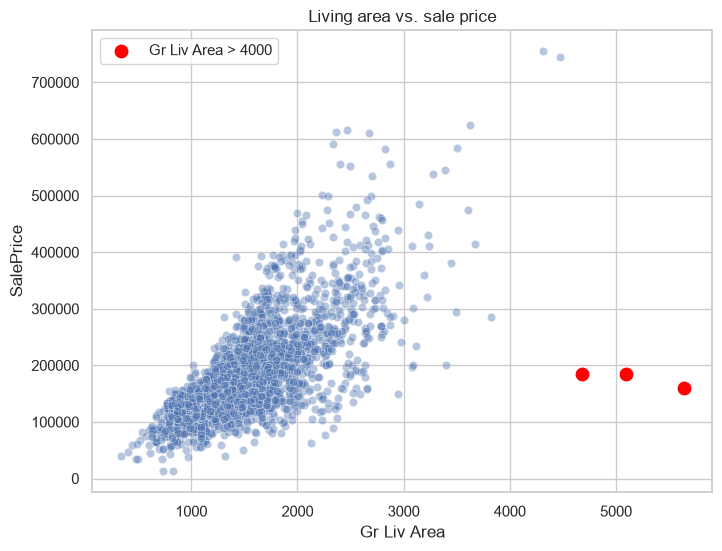

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=housing, x="Gr Liv Area", y="SalePrice", alpha=0.4)
plt.scatter(housing.loc[big, "Gr Liv Area"], housing.loc[big, "SalePrice"],
            color="red", s=80, label="Gr Liv Area > 4000")
plt.title("Living area vs. sale price")
plt.legend()
plt.show()

### 3.3 Outliers

**Plot:** living area vs. sale price. **Question:** are there houses that don't follow the trend?

Price grows with living area, but 5 houses have more than 4000 sq ft. Three of them (4676, 5095 and 5642 sq ft) sold for only 160k–185k, far below the trend. All three have `Sale Condition = Partial`, which means the house wasn't finished when it was assessed, so the price doesn't reflect the full house. We remove these 3 rows. The other two big houses (4316 and 4476 sq ft, about 750k) follow the trend, so we keep them.

We also found one typo: a house built in 2006 has `Garage Yr Blt = 2207`. We replace it with its `Year Built`.

After this the data has 2927 rows.

In [18]:
bad = clean_df["Garage Yr Blt"] > 2010
clean_df.loc[bad, "Garage Yr Blt"] = clean_df.loc[bad, "Year Built"]

outliers = (clean_df["Gr Liv Area"] > 4000) & (clean_df["Sale Condition"] == "Partial")
clean_df = clean_df[~outliers].copy()
print(clean_df.shape)

(2927, 82)


In [19]:
for col in cat_cols:
    top = housing[col].value_counts(normalize=True, dropna=False)
    if top.iloc[0] > 0.95:
        print(col, top.index[0], round(top.iloc[0], 3))

Street Pave 0.996
Utilities AllPub 0.999
Land Slope Gtl 0.952
Condition 2 Norm 0.99
Roof Matl CompShg 0.985
Heating GasA 0.985
Pool QC nan 0.996
Misc Feature nan 0.964


### 3.4 Features we'd drop

- **`Order`, `PID`:** just IDs. `Order` is only the row number (the rows are sorted by sale year).
- **`Garage Area` or `Garage Cars`:** r = 0.89, they measure the same thing.
- **`Garage Yr Blt`:** r = 0.83 with `Year Built`, and 76% of garages were built the same year as the house.
- **Almost constant columns:** [list from the check above, e.g. `Street` is 99.6% one value]. If nearly every house has the same value, the column can't tell houses apart.
- **`Pool QC`, `Misc Feature`:** more than 96% empty. We keep the information as a yes/no feature instead (below).

### 3.5 New features

| Feature | How | Why |
|---|---|---|
| `Total SF` | above-ground living area + basement | total space says more than single floors |
| `Total Bath` | full baths + 0.5 × half baths, basement included | one number instead of four columns |
| `House Age` | `Yr Sold` − `Year Built` | age is easier to read than a year |
| `Has Pool`, `Has Garage` | area > 0 | yes/no versions of mostly empty columns |

In [20]:
clean_df["Total SF"] = clean_df["Gr Liv Area"] + clean_df["Total Bsmt SF"]
clean_df["Total Bath"] = (clean_df["Full Bath"] + 0.5 * clean_df["Half Bath"]
                          + clean_df["Bsmt Full Bath"] + 0.5 * clean_df["Bsmt Half Bath"])
clean_df["House Age"] = clean_df["Yr Sold"] - clean_df["Year Built"]
clean_df["Has Pool"] = (clean_df["Pool Area"] > 0).astype(int)
clean_df["Has Garage"] = (clean_df["Garage Area"] > 0).astype(int)

print("negative ages:", (clean_df["House Age"] < 0).sum())
clean_df = clean_df.drop(columns=["Order", "PID"])
print(clean_df.shape)

negative ages: 0
(2927, 85)


### 3.6 Data from outside

- **Distance to downtown / Iowa State University:** location matters a lot and `Neighborhood` is only a rough hint.
- **School quality and crime rate of the area:** both affect what people pay.
- **Mortgage interest rates at the sale date:** the data covers 2006–2010, including the housing crash.
- **Local income / unemployment:** shows what people in the area can afford.

In [21]:
print(clean_df.shape)
left = clean_df.isna().sum()
left[left > 0]

(2927, 85)


Garage Yr Blt    159
dtype: int64

### 3.7 Distribution of sale prices

**Plot:** histogram of `SalePrice`, raw next to log-transformed. **Question:** what does the price distribution look like?

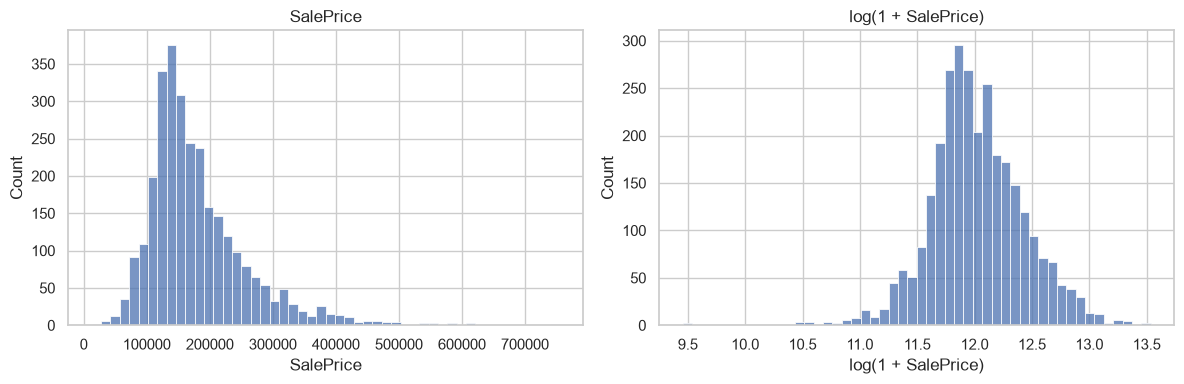

mean: 180801 | median: 160000
min: 12789 | max: 755000
skew raw: 1.74 | skew log: -0.01


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_df["SalePrice"], bins=50, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(clean_df["SalePrice"]), bins=50, ax=axes[1])
axes[1].set_title("log(1 + SalePrice)")
axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print("mean:", round(clean_df["SalePrice"].mean()), "| median:", round(clean_df["SalePrice"].median()))
print("min:", clean_df["SalePrice"].min(), "| max:", clean_df["SalePrice"].max())
print("skew raw:", round(clean_df["SalePrice"].skew(), 2),
      "| skew log:", round(np.log1p(clean_df["SalePrice"]).skew(), 2))

**What the plot shows:** most houses sell between about 100k and 250k, with the peak around 140k–150k. The distribution is skewed to the right: a few expensive houses (up to about 750k) form a long tail, which pulls the mean ([mean]) above the median ([median]). After the log transform the shape is much more symmetric and bell-shaped (skew went from [raw skew] to [log skew]), so cheap and mid-range houses are easier to read. A few very cheap houses still show up as a small tail on the left.

### Summary

After cleaning, the data has 2927 rows and 85 columns. The only remaining NaN is `Garage Yr Blt` (159 rows: houses without a garage, plus a couple where the year is missing). We left it empty on purpose, since 0 would be a fake year.

### 3.8 Sale price by quality level

**Plot:** violin plot of `SalePrice` for five quality levels. **Question:** does the quality of a house show up in its price, and how much do prices vary within one quality level?

To get one quality number per house, we turn five ratings (`Exter Qual`, `Kitchen Qual`, `Bsmt Qual`, `Heating QC`, `Fireplace Qu`) into points (Ex = 5, Gd = 4, TA = 3, Fa = 2, Po = 1, no basement/fireplace = 0) and add them up. The score goes from 0 to 25, and we group it into five levels.

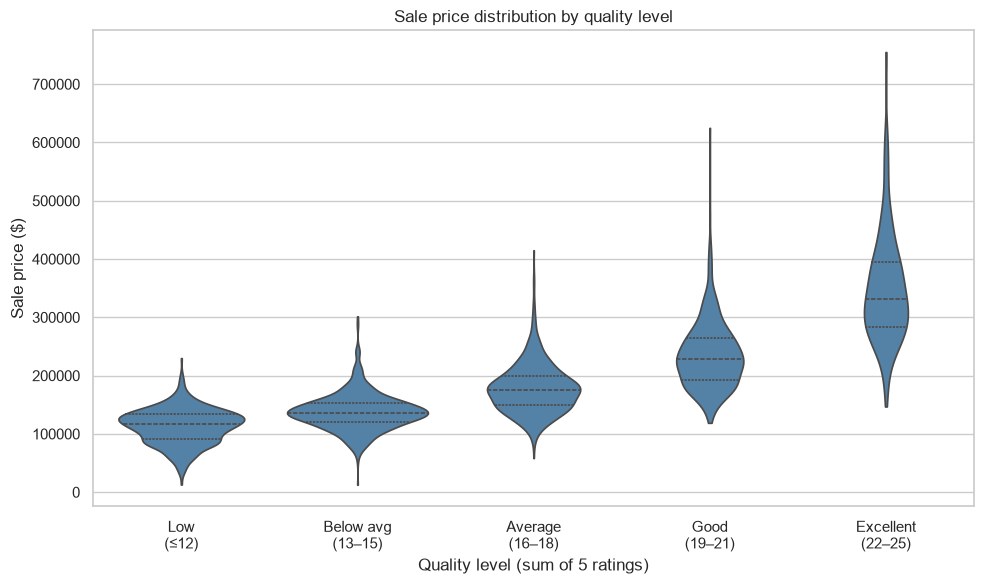

In [23]:
from preprocessing import add_quality_scores

heat_df = add_quality_scores(clean_df)
heat_df["Quality Score"] = heat_df.filter(like=" Num").sum(axis=1)

labels = ["Low\n(≤12)", "Below avg\n(13–15)", "Average\n(16–18)", "Good\n(19–21)", "Excellent\n(22–25)"]
heat_df["Quality Level"] = pd.cut(heat_df["Quality Score"], bins=[0, 12, 15, 18, 21, 25], labels=labels)

plt.figure(figsize=(10, 6))
sns.violinplot(data=heat_df, x="Quality Level", y="SalePrice", color="steelblue",
               inner="quartile", cut=0)
plt.grid(axis="x", visible=False)
plt.ylabel("Sale price ($)")
plt.xlabel("Quality level (sum of 5 ratings)")
plt.title("Sale price distribution by quality level")
plt.tight_layout()
plt.show()

**What the plot shows:** every step up in quality raises the price, and the steps get bigger at the top. The median goes from about 117k (Low) to 138k (Below avg), 176k (Average), 229k (Good) and 333k (Excellent). So the jump from Good to Excellent (about +100k) is five times bigger than the one from Low to Below avg (about +20k).

The violins also get taller: low-quality houses stay below about 230k, while excellent ones go from 150k up to 750k. The levels overlap a lot, for example a good house can cost anything between 120k and 620k. So quality is a strong feature, but for the better houses other things (size, neighborhood) decide a big part of the price.

### 3.9 When are houses sold?

**Plot:** heatmap of the number of houses sold per month and year. **Question:** is there a season for selling houses, and is any period missing from the data?

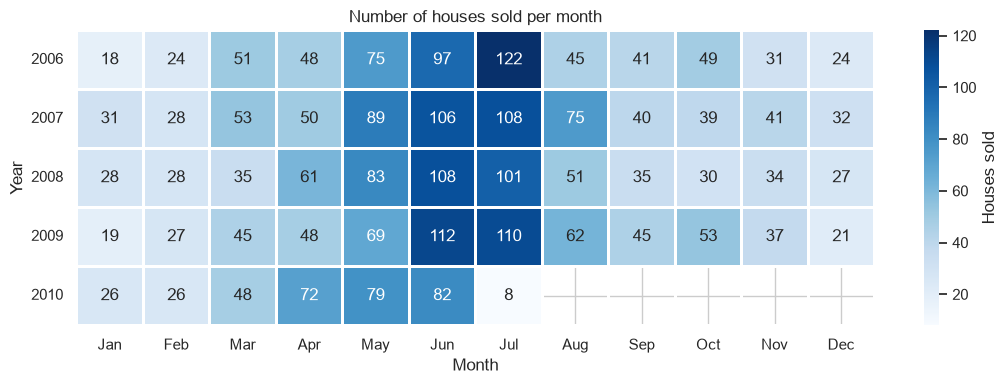

In [24]:
sales = clean_df.pivot_table(index="Yr Sold", columns="Mo Sold", values="SalePrice", aggfunc="count")
sales.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(11, 4))
sns.heatmap(sales, annot=True, fmt=".0f", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Houses sold"})
plt.xlabel("Month")
plt.ylabel("Year")
plt.title("Number of houses sold per month")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**What the plot shows:** there is a clear season. June and July have about 100–120 sales every year, while December to February have only 18–32. Almost half of all sales (46%) happen in May, June and July. A likely reason is that families prefer to move in the summer, between school years, but we didn't check this.

The number of sales per year is quite stable (621–692 from 2006 to 2009), even in 2008, which fits what we saw in 4.2. The data stops in July 2010 (only 8 sales that month), so 2010 is not a full year and we should be careful when comparing it to the others.

### 3.10 Price per square foot by neighborhood

**Plot:** median sale price per square foot of living area for each neighborhood with at least 20 sales. **Question:** how much does location matter once we take the size of the house out of the picture?

Dividing the price by `Gr Liv Area` removes the effect of size, so a neighborhood doesn't look expensive just because its houses are big. Darker bars are above the median of all houses.

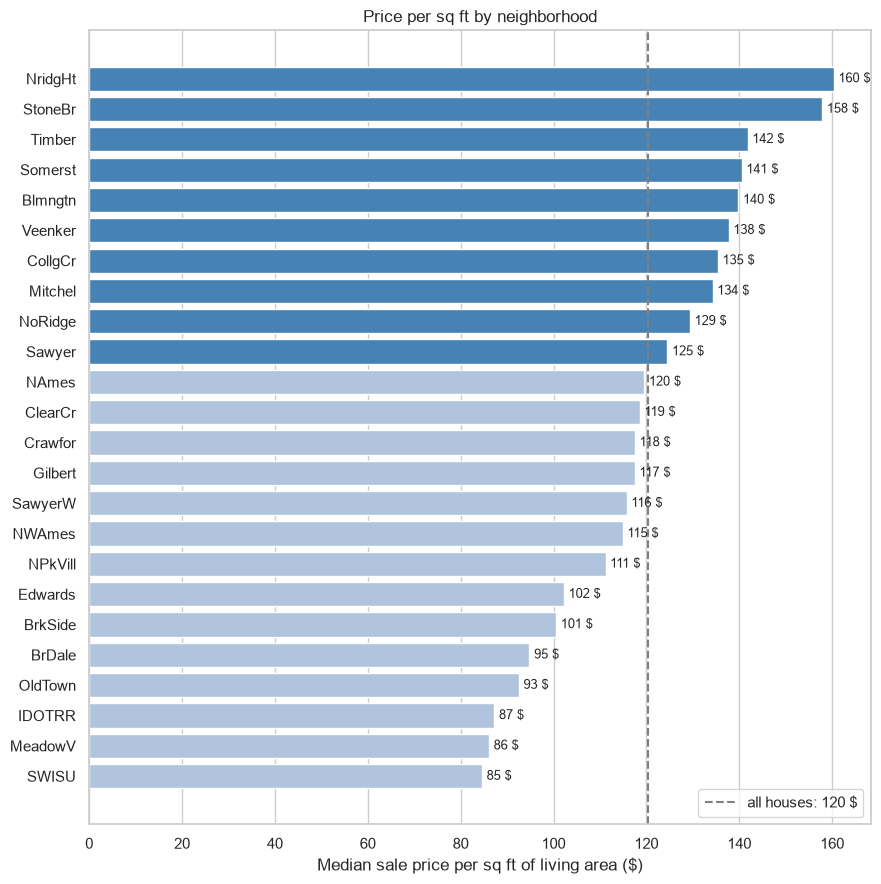

In [25]:
df = clean_df.copy()
df["Price per SF"] = df["SalePrice"] / df["Gr Liv Area"]

nb = df.groupby("Neighborhood")["Price per SF"].agg(["count", "median"])
nb = nb[nb["count"] >= 20].sort_values("median") 
overall = df["Price per SF"].median()

plt.figure(figsize=(9, 9))
colors = ["steelblue" if v >= overall else "lightsteelblue" for v in nb["median"]]
plt.barh(nb.index, nb["median"], color=colors)
for i, v in enumerate(nb["median"]):
    plt.text(v + 1, i, f"{v:.0f} $", va="center", fontsize=9)
plt.axvline(overall, color="gray", linestyle="--", label=f"all houses: {overall:.0f} $")
plt.grid(axis="y", visible=False)
plt.xlabel("Median sale price per sq ft of living area ($)")
plt.title("Price per sq ft by neighborhood")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What the plot shows:** location matters a lot. The median over all houses is 120 \$ per sq ft, but it goes from 85 \$ in `SWISU` (south and west of Iowa State University) to 160 \$ in `NridgHt` (Northridge Heights). So the same amount of living space costs almost twice as much in the most expensive neighborhood as in the cheapest one. The cheap end (`SWISU`, `MeadowV`, `IDOTRR`, `OldTown`, `BrDale`) is mostly older areas near the center, the railroad and the university.

For lab 2 this means `Neighborhood` should be a useful feature, and it supports the idea from 3.6 of adding outside data about the location.

### 3.11 Sale price by garage size

**Plot:** box plot of `SalePrice` for each garage size (number of cars, 3 or more grouped together). **Question:** do houses with bigger garages sell for more?

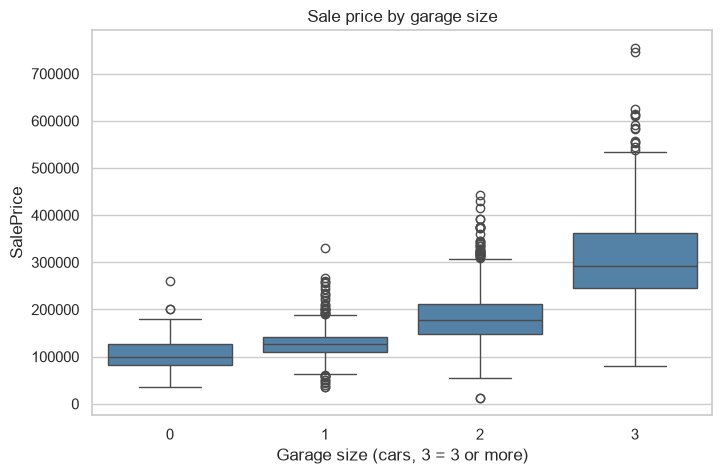

Garage Cars
0    100000.0
1    127000.0
2    177000.0
3    293077.0
Name: SalePrice, dtype: float64


In [26]:
garage = clean_df["Garage Cars"].clip(upper=3).astype(int)  

plt.figure(figsize=(8, 5))
sns.boxplot(x=garage, y=clean_df["SalePrice"], color="steelblue")
plt.xlabel("Garage size (cars, 3 = 3 or more)")
plt.ylabel("SalePrice")
plt.title("Sale price by garage size")
plt.show()

print(clean_df.groupby(garage)["SalePrice"].median())

**What the plot shows:** yes, the median price grows with every extra car: 100k without a garage, 127k for 1 car, 177k for 2 cars and 293k for 3 or more. The step from 2 to 3+ cars (+116k) is by far the biggest.

But the garage is probably not the only reason. Big garages come with big, new, well-built houses, so part of this effect really comes from size and quality. This is the same problem as in 4.4: a third feature can make a connection look stronger than it is.

## 4. More plots

The plots so far looked at missing values, outliers, the price distribution, quality, the season, neighborhoods and garages. The next six plots answer questions we haven't covered yet: which numeric features are connected (heatmap), whether the 2008 housing crisis shows up in the prices, whether the type of sale matters, whether new houses are expensive because they are new or because they are better, how some important features are distributed, and what people change when they renovate.

### 4.1 Correlation heatmap

**Plot:** heatmap of the correlations between `SalePrice` and 15 key numeric features (after cleaning). **Question:** which features go together with the price, and which ones carry the same information?

Red means both features grow together, blue means one grows while the other falls. We only show the lower half, because the matrix is symmetric.

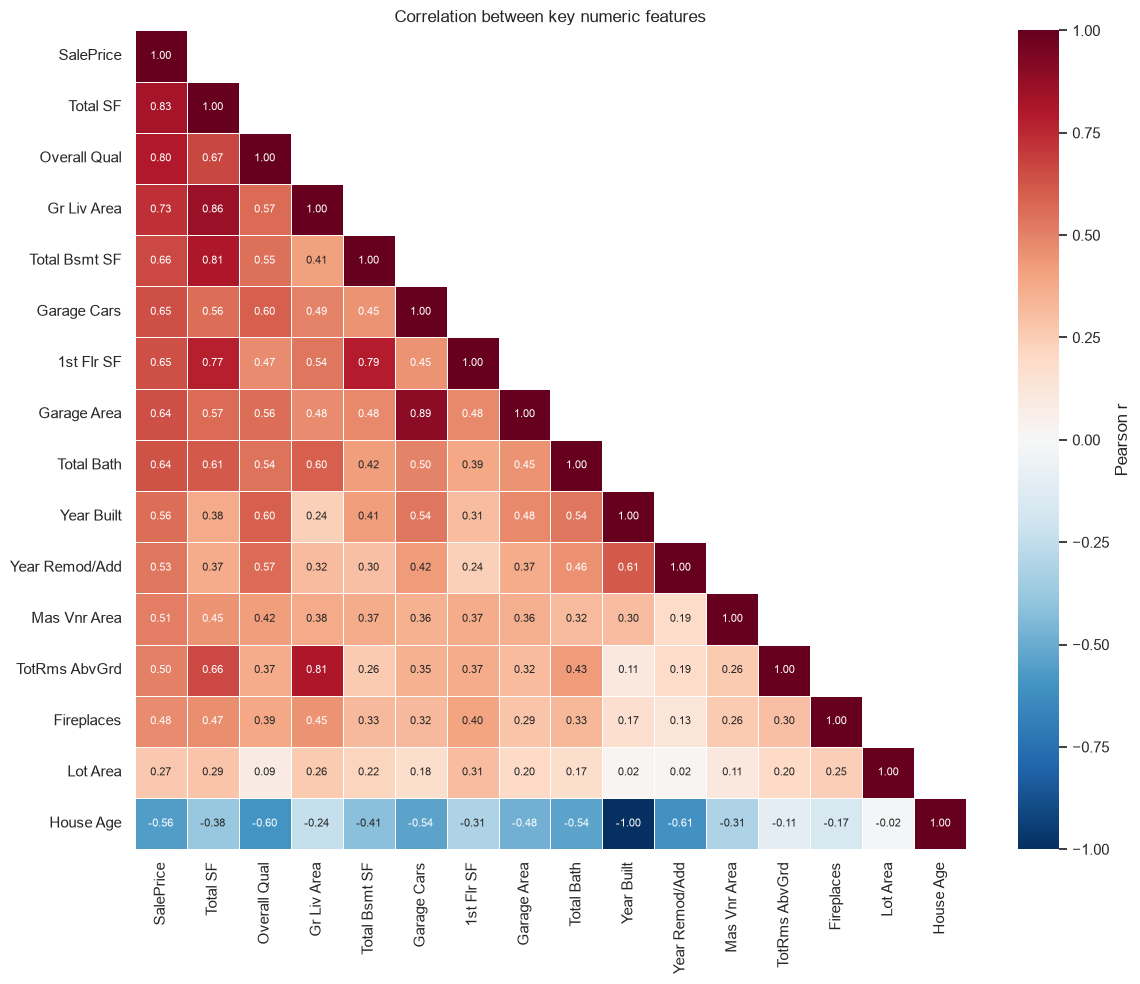

In [27]:
heat_cols = ["SalePrice", "Total SF", "Overall Qual", "Gr Liv Area", "Total Bsmt SF", "Garage Cars",
             "1st Flr SF", "Garage Area", "Total Bath", "Year Built", "Year Remod/Add", "Mas Vnr Area",
             "TotRms AbvGrd", "Fireplaces", "Lot Area", "House Age"]
corr_matrix = clean_df[heat_cols].corr()
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "Pearson r"})
plt.grid(False)
plt.title("Correlation between key numeric features")
plt.tight_layout()
plt.show()

**What the plot shows:**
- **Price (first column):** the strongest are `Total SF` (0.83) and `Overall Qual` (0.80), then the size features `Gr Liv Area`, `Total Bsmt SF` and `1st Flr SF`, the garage and the bathrooms (0.64–0.73). The age of the house matters less (`Year Built` 0.56). `Lot Area` is weak (0.27): the size of the land says much less about the price than the size of the house.
- **Redundant pairs:** `Year Built` and `House Age` have r = −1.00. All sales happen within five years (2006–2010), so the age is just the build year flipped, and we only need one of them. `Garage Cars` and `Garage Area` (0.89), `Gr Liv Area` and `TotRms AbvGrd` (0.81) and `Total Bsmt SF` and `1st Flr SF` (0.79) also overlap a lot. `Total SF` is built from `Gr Liv Area` and `Total Bsmt SF`, so it correlates with both (0.86 and 0.81).
- **Why this matters for lab 2:** if a linear model gets two features that say almost the same thing (multicollinearity), the coefficients become unstable and hard to interpret. So from each redundant pair we would keep one.

Pearson correlation only measures straight-line relationships. `Overall Qual` is ordinal, so its r only tells us that higher ratings go with higher prices, not that every step adds the same amount.

### 4.2 Sale price over the years

**Plot:** median sale price per year, with a band for the middle 50% of prices (25th to 75th percentile). **Question:** does the US housing crisis that started in 2007–2008 show up in Ames?

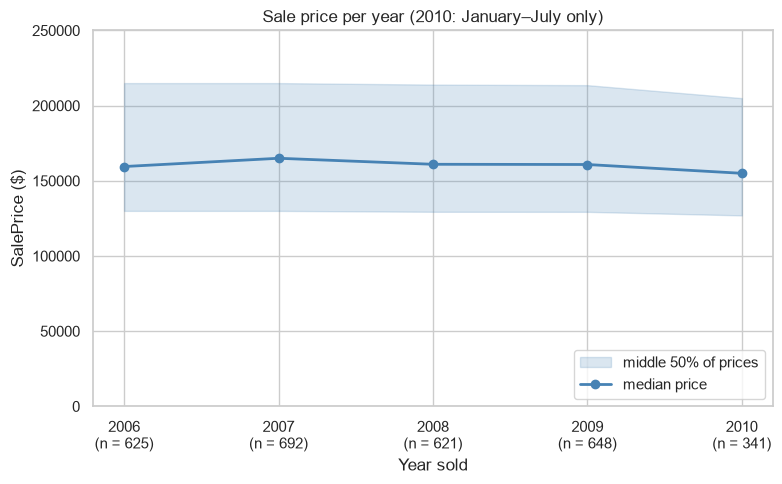

             0.25      0.50      0.75
Yr Sold                              
2006     130000.0  159500.0  215000.0
2007     130000.0  165000.0  215000.0
2008     129400.0  161000.0  214000.0
2009     129375.0  160850.0  213625.0
2010     127000.0  155000.0  205000.0


In [28]:
yearly = clean_df.groupby("Yr Sold")["SalePrice"].quantile([0.25, 0.5, 0.75]).unstack()
year_counts = clean_df["Yr Sold"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.fill_between(yearly.index, yearly[0.25], yearly[0.75], color="steelblue", alpha=0.2,
                 label="middle 50% of prices")
plt.plot(yearly.index, yearly[0.5], color="steelblue", marker="o", linewidth=2, label="median price")
plt.xticks(yearly.index, [f"{y}\n(n = {year_counts[y]})" for y in yearly.index])
plt.ylim(0, 250000)
plt.xlabel("Year sold")
plt.ylabel("SalePrice ($)")
plt.title("Sale price per year (2010: January–July only)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(yearly.round())

**What the plot shows:** hardly at all. The median stays between 155k and 165k every year (159.5k in 2006, 165k in 2007, 161k in 2008, 160.9k in 2009, 155k in 2010), and the middle 50% stays at about 130k–215k. 2010 is a bit lower, but it only covers January to July and has about half the sales, so we can't conclude much from it. A possible reason is that Ames is a small university town with a stable local market, but we didn't check this.

For lab 2 this means that `Yr Sold` on its own will probably not help much to predict the price.

### 4.3 Sale price by sale condition

**Plot:** box plot of the price for each `Sale Condition`, sorted by median. **Question:** does the kind of sale change the price?

From the description file: `Normal` is a normal sale, `Abnorml` an abnormal sale (trade, foreclosure, short sale), `Family` a sale between family members, `Alloca` two linked properties sold together, `AdjLand` a purchase of the neighboring land, and `Partial` a house that wasn't finished when it was last assessed (new houses).

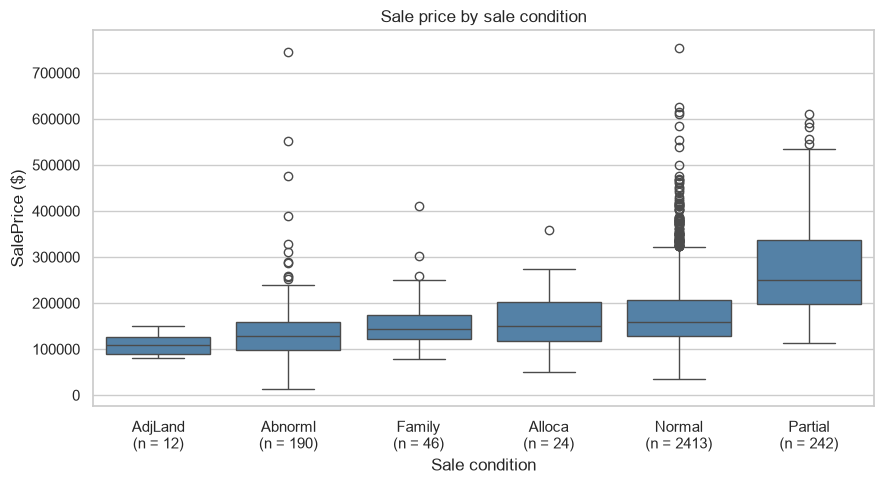

Sale Condition
AdjLand    110000.0
Abnorml    129450.0
Family     144400.0
Alloca     149617.0
Normal     159000.0
Partial    250290.0
Name: SalePrice, dtype: float64
Partial sales with Sale Type 'New': 0.98
Partial sales at most 1 year old: 0.95


In [29]:
cond_order = clean_df.groupby("Sale Condition")["SalePrice"].median().sort_values().index
cond_counts = clean_df["Sale Condition"].value_counts()

plt.figure(figsize=(9, 5))
sns.boxplot(data=clean_df, x="Sale Condition", y="SalePrice", order=cond_order, color="steelblue")
plt.xticks(range(len(cond_order)), [f"{c}\n(n = {cond_counts[c]})" for c in cond_order])
plt.xlabel("Sale condition")
plt.ylabel("SalePrice ($)")
plt.title("Sale price by sale condition")
plt.tight_layout()
plt.show()

print(clean_df.groupby("Sale Condition")["SalePrice"].median().sort_values())
partial = clean_df[clean_df["Sale Condition"] == "Partial"]
print("Partial sales with Sale Type 'New':", round((partial["Sale Type"] == "New").mean(), 2))
print("Partial sales at most 1 year old:", round((partial["House Age"] <= 1).mean(), 2))

**What the plot shows:** most houses (2413 of 2927, 82%) are normal sales, with a median of 159k. `Partial` sales are much more expensive (median 250k), but not because of the kind of sale: 98% of them have `Sale Type = New` and 95% are at most one year old. So `Partial` mostly means "new house". At the other end, `Abnorml` sales (129k) are cheaper, which fits foreclosures and short sales, where the seller has to sell fast. `AdjLand` has the lowest median (110k), but it has only 12 houses, so it isn't reliable.

So `Sale Condition` is useful, but `Partial` overlaps with `House Age` and `Sale Type`. The three outliers we removed in 3.3 were also `Partial` sales, even though this is usually the most expensive group.

### 4.4 Year built vs. sale price, by quality

**Plot:** scatter plot of `Year Built` and `SalePrice`, colored by `Overall Qual`. **Question:** are new houses more expensive because they are new, or because they are built better?

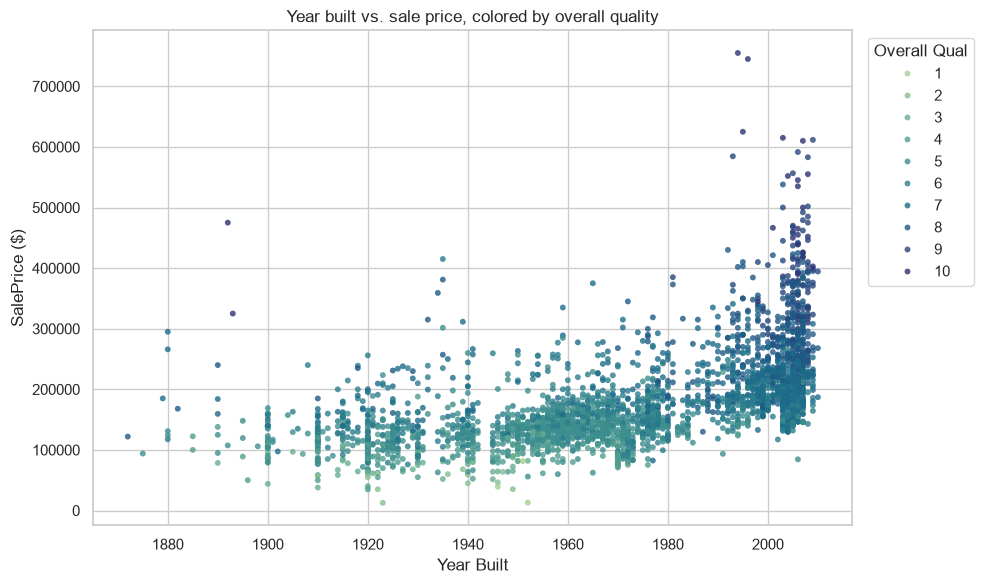

Year Built vs SalePrice: 0.56
Year Built vs Overall Qual: 0.6
only Overall Qual = 4 (226 houses): r = 0.25
only Overall Qual = 5 (825 houses): r = 0.32
only Overall Qual = 6 (732 houses): r = 0.32
only Overall Qual = 7 (602 houses): r = 0.19
only Overall Qual = 8 (350 houses): r = 0.20
Year Built
(1870, 1950]    5.19
(1950, 1980]    5.40
(1980, 2000]    6.76
(2000, 2010]    7.47
Name: Overall Qual, dtype: float64


In [30]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean_df, x="Year Built", y="SalePrice", hue="Overall Qual", palette="crest",
                s=18, alpha=0.8, linewidth=0, legend="full")
plt.legend(title="Overall Qual", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.ylabel("SalePrice ($)")
plt.title("Year built vs. sale price, colored by overall quality")
plt.tight_layout()
plt.show()

print("Year Built vs SalePrice:", round(clean_df["Year Built"].corr(clean_df["SalePrice"]), 2))
print("Year Built vs Overall Qual:", round(clean_df["Year Built"].corr(clean_df["Overall Qual"]), 2))
for q in range(4, 9):
    same = clean_df[clean_df["Overall Qual"] == q]
    print(f"only Overall Qual = {q} ({len(same)} houses): r = {same['Year Built'].corr(same['SalePrice']):.2f}")
print(clean_df.groupby(pd.cut(clean_df["Year Built"], [1870, 1950, 1980, 2000, 2010]))["Overall Qual"].mean().round(2))

**What the plot shows:** newer houses are more expensive (r = 0.56), and most of the expensive ones (dark points) were built after 1990. But the colors show that newer houses are also better: `Year Built` and `Overall Qual` have r = 0.60, and the average quality goes up from 5.2 (built until 1950) to 7.5 (built 2001–2010). If we only compare houses with the same quality, the connection between build year and price gets much weaker: r is between 0.19 and 0.32 for each quality level from 4 to 8.

So a big part of "new = expensive" is really "new = better quality", and age only has a small effect of its own. This is an example of a third feature (quality) that makes a correlation look stronger than it is, the same idea as the spurious correlations in the bonus part.

### 4.5 Distributions of important features

**Plot:** histograms of `Lot Area`, `Gr Liv Area`, `Total Bsmt SF` and `Year Built`. **Question:** how are these values spread, and do we need to transform them before using them in a model?

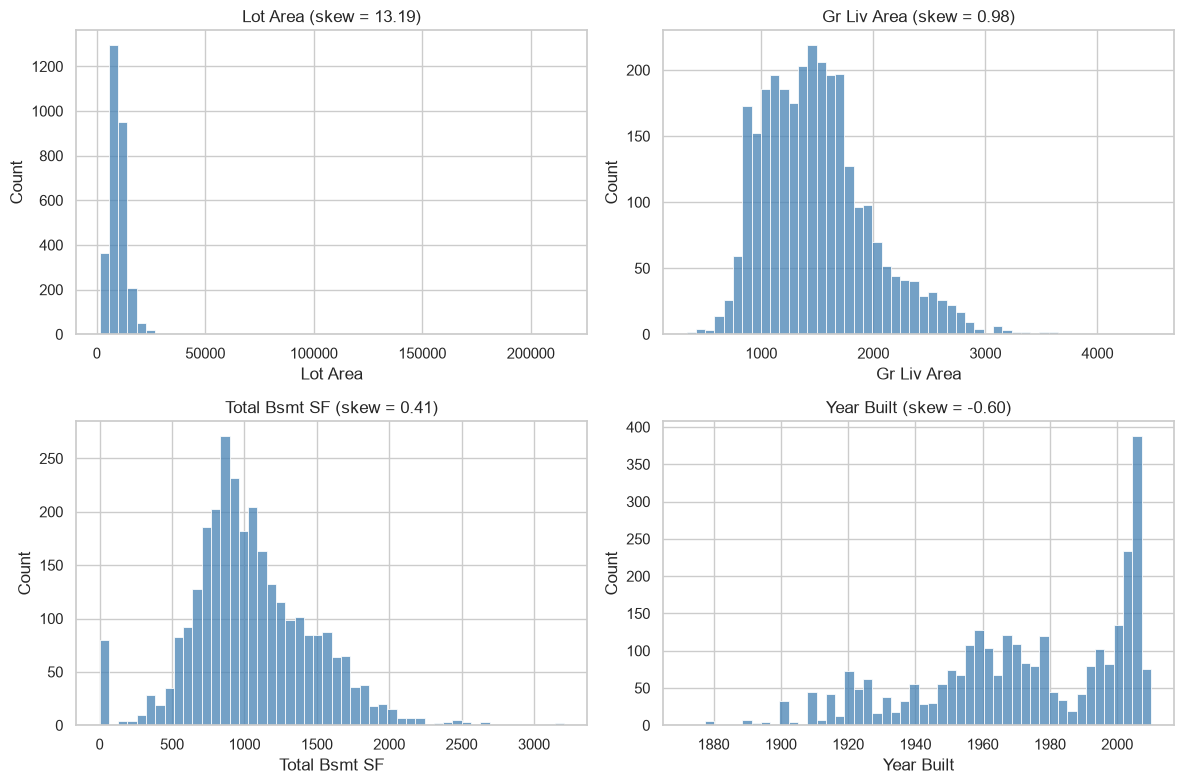

       Lot Area  Gr Liv Area  Total Bsmt SF  Year Built
count    2927.0       2927.0         2927.0      2927.0
mean    10109.0       1496.0         1047.0      1971.0
std      7783.0        492.0          423.0        30.0
min      1300.0        334.0            0.0      1872.0
25%      7439.0       1126.0          792.0      1954.0
50%      9430.0       1442.0          990.0      1973.0
75%     11523.0       1741.0         1300.0      2000.0
max    215245.0       4476.0         3206.0      2010.0
skew of log(1 + Lot Area): -0.53
houses without basement: 80
Year Built
[1870, 1880)      3
[1880, 1890)      8
[1890, 1900)     15
[1900, 1910)     40
[1910, 1920)    110
[1920, 1930)    196
[1930, 1940)    109
[1940, 1950)    151
[1950, 1960)    340
[1960, 1970)    357
[1970, 1980)    364
[1980, 1990)    120
[1990, 2000)    334
[2000, 2010)    777
[2010, 2020)      3
Name: count, dtype: int64


In [31]:
dist_cols = ["Lot Area", "Gr Liv Area", "Total Bsmt SF", "Year Built"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, dist_cols):
    sns.histplot(clean_df[col], bins=50, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew = {clean_df[col].skew():.2f})")
plt.tight_layout()
plt.show()

print(clean_df[dist_cols].describe().round())
print("skew of log(1 + Lot Area):", round(np.log1p(clean_df["Lot Area"]).skew(), 2))
print("houses without basement:", (clean_df["Total Bsmt SF"] == 0).sum())
print(pd.cut(clean_df["Year Built"], range(1870, 2021, 10), right=False).value_counts().sort_index())

**What the plot shows:**
- **`Lot Area`** is extremely skewed (skew 13.19). Half of the lots are smaller than 9430 sq ft and 75% are smaller than 11,523 sq ft, but the biggest one has 215,245 sq ft. These few huge lots squeeze all the other houses into the first bars. After a log transform the skew drops to −0.53, so for lab 2 we would use `log(Lot Area)`.
- **`Gr Liv Area`** is also skewed to the right, but much less (0.98): half of the houses have between 1126 and 1741 sq ft, and a few large houses form the tail.
- **`Total Bsmt SF`** is almost bell-shaped around 1000 sq ft, except for the bar at 0: these are the 80 houses without a basement. A model would read 0 as "a very small basement", so a yes/no feature `Has Basement` could help.
- **`Year Built`** shows two building waves: 1950–1979 (1061 houses) and 1990–2009 (1111 houses, 777 of them in the 2000s alone). In the 1980s in between, only 120 houses were built. The data doesn't tell us why. A possible reason is the very high US interest rates at the start of the 1980s, which would be one more argument for adding interest rates as outside data (3.6).

### 4.6 What gets renovated?

**Plot:** for houses built 1950–1985, the share of houses where each part of the house is rated good or excellent (`Gd`/`Ex`), once for houses that were never remodeled and once for remodeled ones. **Question:** when people renovate, which parts of the house do they change the most?

The data has no column that says *what* was renovated, only `Year Remod/Add` (equal to `Year Built` if there was no remodel). So we compare houses of the same age: if remodeled houses have a much better kitchen than houses that were never touched, the kitchen is probably part of the renovation. We count a house as remodeled if `Year Remod/Add` is at least 5 years after `Year Built` (a smaller gap is more likely the end of the construction). We only use houses built 1950–1985, because remodel years before 1950 are not recorded (all of them are set to 1950) and newer houses had little time to be remodeled. There are no quality columns for bathrooms, so for them we compare the number of bathrooms instead.

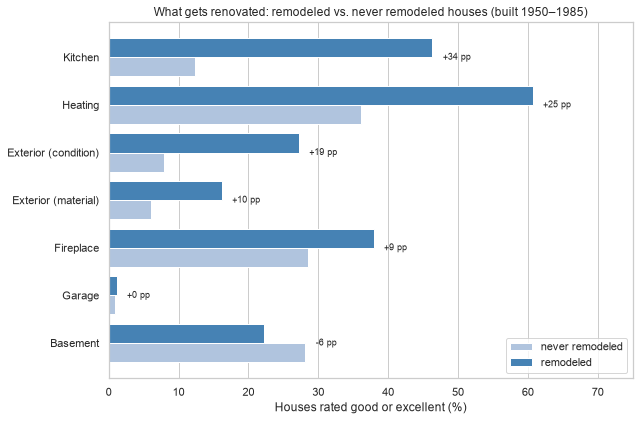

Remodeled
never remodeled    867
remodeled          272
Name: count, dtype: int64
                part  never remodeled  remodeled  difference
             Kitchen             12.3       46.3        34.0
             Heating             36.1       60.7        24.6
Exterior (condition)              8.0       27.2        19.2
 Exterior (material)              6.0       16.2        10.2
           Fireplace             28.5       37.9         9.4
              Garage              0.9        1.1         0.3
            Basement             28.1       22.3        -5.9
           Full Bath  Half Bath  Bsmt Full Bath  Total Bath
Remodeled                                                  
False           1.33       0.30            0.43        1.95
True            1.34       0.29            0.59        2.13


In [ ]:
parts = {"Kitchen Qual": "Kitchen", "Heating QC": "Heating", "Exter Cond": "Exterior (condition)",
         "Exter Qual": "Exterior (material)", "Fireplace Qu": "Fireplace", "Bsmt Qual": "Basement",
         "Garage Qual": "Garage"}
remod_df = clean_df[clean_df["Year Built"].between(1950, 1985)].copy()
remod_df["Remodeled"] = remod_df["Year Remod/Add"] - remod_df["Year Built"] >= 5

def good_share(group, col):
    has_part = group[group[col] != "None"]  # e.g. houses without a fireplace don't count
    return has_part[col].isin(["Gd", "Ex"]).mean() * 100

rows = []
for col, name in parts.items():
    not_remod = good_share(remod_df[~remod_df["Remodeled"]], col)
    remod = good_share(remod_df[remod_df["Remodeled"]], col)
    rows.append({"part": name, "never remodeled": not_remod, "remodeled": remod, "difference": remod - not_remod})
parts_df = pd.DataFrame(rows).sort_values("difference")

plt.figure(figsize=(9, 6))
y = np.arange(len(parts_df))
plt.barh(y - 0.2, parts_df["never remodeled"], height=0.4, color="lightsteelblue", label="never remodeled")
plt.barh(y + 0.2, parts_df["remodeled"], height=0.4, color="steelblue", label="remodeled")
for i, d in enumerate(parts_df["difference"]):
    plt.text(max(parts_df.iloc[i][["never remodeled", "remodeled"]]) + 1.5, i, f"{d:+.0f} pp",
             va="center", fontsize=9)
plt.yticks(y, parts_df["part"])
plt.xlim(0, 75)
plt.grid(axis="y", visible=False)
plt.xlabel("Houses rated good or excellent (%)")
plt.title("What gets renovated: remodeled vs. never remodeled houses (built 1950–1985)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(remod_df["Remodeled"].value_counts().rename({True: "remodeled", False: "never remodeled"}))
print(parts_df.iloc[::-1].round(1).to_string(index=False))
print(remod_df.groupby("Remodeled")[["Full Bath", "Half Bath", "Bsmt Full Bath", "Total Bath"]].mean().round(2))

**What the plot shows:** 272 of the 1139 houses built 1950–1985 were remodeled. The biggest difference is the **kitchen**: 46% of the remodeled houses have a good or excellent kitchen, against only 12% of the houses that were never remodeled (+34 percentage points). Next come the **heating** (+25 pp, from 36% to 61%) and the **outside of the house**: its condition (+19 pp) and, less often, the material itself (+10 pp). Fireplaces change a little (+9 pp), and garages almost not at all (+0 pp; only 1% of all garages are rated good, remodeled or not).

The **basement** is even slightly worse in remodeled houses (−6 pp). This makes sense: according to the description file, `Bsmt Qual` rates the *height* of the basement, which a renovation can't change. **Bathrooms** have no quality column, but the number of bathrooms above ground is the same for both groups (1.33 vs. 1.34 full baths, 0.30 vs. 0.29 half baths). The only difference is in the basement (0.43 vs. 0.59 full baths), so when a bathroom is added, it usually goes into the basement. So in Ames people renovate the kitchen much more than they add bathrooms.

These numbers only show what remodeled houses *have*, not what was actually done, and some differences could come from houses that were better from the start. But the pattern is clear: kitchen, heating and the outside of the house are what people change, and this is also why `Year Remod/Add` is connected to the price.

## 5. Bonus: linear regression

For the bonus we pick two pairs of features that look linearly related, fit a straight line with scikit-learn on 80% of the houses, and test it on the other 20%.

### 5.1 First pair: total area and sale price

Our first pair is `Total SF` (living area + basement, the feature we built in 3.5) and `SalePrice`. **Why we expect a linear relation:** the price of a house is roughly its size times a price per square foot, so more space should mean a proportionally higher price.

**Plot:** scatter plot of `Total SF` and `SalePrice`. **Question:** do the points really follow a straight line?

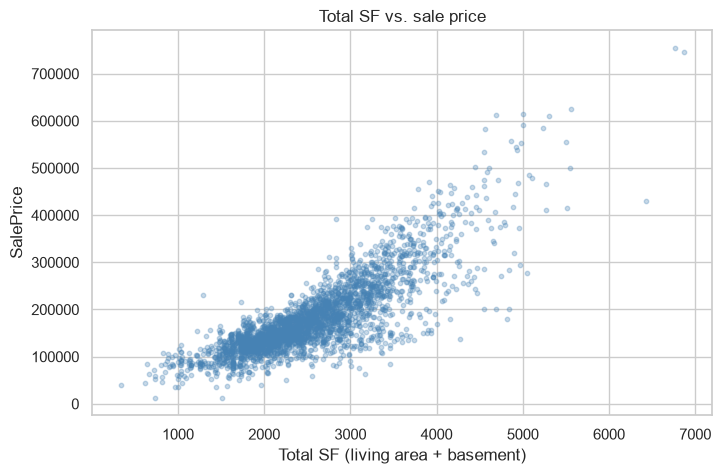

correlation: 0.83


In [33]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["Total SF"], clean_df["SalePrice"], alpha=0.3, s=10, color="steelblue")
plt.xlabel("Total SF (living area + basement)")
plt.ylabel("SalePrice")
plt.title("Total SF vs. sale price")
plt.show()

print("correlation:", round(clean_df["Total SF"].corr(clean_df["SalePrice"]), 2))

**What the plot shows:** the points form a clear rising band, and the correlation is 0.83, the strongest of all numeric features (see 4.1). Houses with 1000–2000 sq ft mostly cost around 100k–200k, and houses with 4000–5000 sq ft around 300k–600k.

The band gets wider for bigger houses: the price of a large house varies much more than the price of a small one. A straight line can follow the trend, but its errors will be bigger for big houses.

Coefficient: 84.3
Intercept: -33445.02
Root mean squared error: 47459
R^2 on test data: 0.72


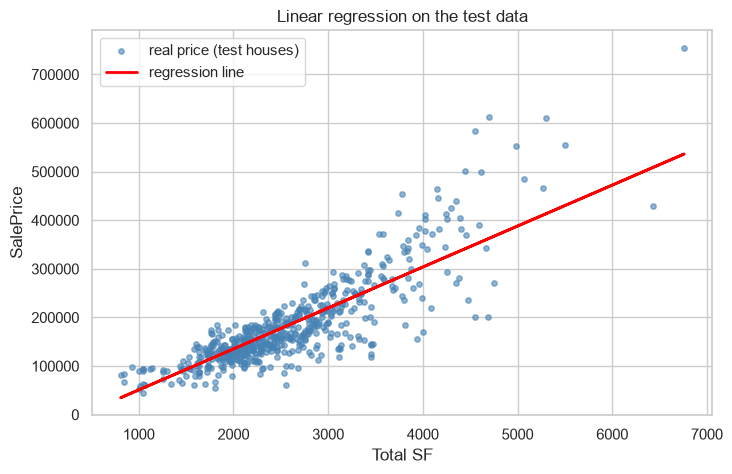

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = clean_df[["Total SF"]]
y = clean_df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Coefficient:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))
print("Root mean squared error:", round(mean_squared_error(y_test, y_pred) ** 0.5))
print("R^2 on test data:", round(r2_score(y_test, y_pred), 2))

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="steelblue", s=15, alpha=0.6, label="real price (test houses)")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="regression line")
plt.xlabel("Total SF")
plt.ylabel("SalePrice")
plt.title("Linear regression on the test data")
plt.legend()
plt.show()

**What the plot shows:** the line is `SalePrice ≈ 84.3 × Total SF − 33,445`, so every extra square foot adds about 84 \$ to the price. On the test data R² = 0.72, which means the size alone explains about 72% of the differences in price. The typical error (RMSE) is about 47,000 \$.

The negative intercept doesn't mean anything real (no house has 0 sq ft). It's only where the line crosses the axis, far away from our data.

**Real vs. predicted** for five test houses, and predictions for some house sizes we chose:

In [35]:
compare = X_test.copy()
compare["real price"] = y_test
compare["predicted"] = y_pred.round()
compare["difference"] = compare["predicted"] - compare["real price"]
print(compare.head(5))

new_houses = pd.DataFrame({"Total SF": [1000, 2000, 3000, 4000]})
new_houses["predicted"] = model.predict(new_houses).round()
print(new_houses)

      Total SF  real price  predicted  difference
2393    3443.0      298236   256814.0    -41422.0
196     2288.0      132000   159443.0     27443.0
2310    2338.0      183500   163658.0    -19842.0
1732    2444.0      198444   172594.0    -25850.0
1100    3343.0      250000   248383.0     -1617.0
   Total SF  predicted
0      1000    50859.0
1      2000   135163.0
2      3000   219467.0
3      4000   303771.0


**What the table shows:** for the five test houses the error goes from about 1,600 \$ to 41,000 \$. Two of them have almost the same size (3343 and 3443 sq ft) but sold for 250k and 298k, so size can't explain everything: quality (3.8) and location (3.10) make up the rest. For the sizes we chose, the model predicts about 51k for 1000 sq ft, 135k for 2000, 219k for 3000 and 304k for 4000 sq ft, so each extra 1000 sq ft adds about 84k.

**What this means for lab 2:** `Total SF` is a very good single feature, but a model will need more features (quality, neighborhood) to get closer. Since the errors grow with the size of the house, predicting `log(SalePrice)` (see 3.7) could also help.

### 5.2 Second pair: basement area and first floor area

Our second pair is `Total Bsmt SF` (basement area) and `1st Flr SF` (first floor area). **Why we expect a linear relation:** a basement is dug under the house, and the first floor stands on the basement walls. So in most houses the basement has the same outline as the first floor, and the two areas should grow together.

Houses without a basement have `Total Bsmt SF = 0` but still have a first floor. On the scatter plot they form a vertical line at 0 that has nothing to do with the relation we want to model, so we fit the regression only on the 2847 houses with a basement.

houses with a basement: 2847
r, all houses: 0.79
r, only houses with a basement: 0.88
Coefficient: 0.84
Intercept: 256.47
Root mean squared error: 154
R^2 on test data: 0.82


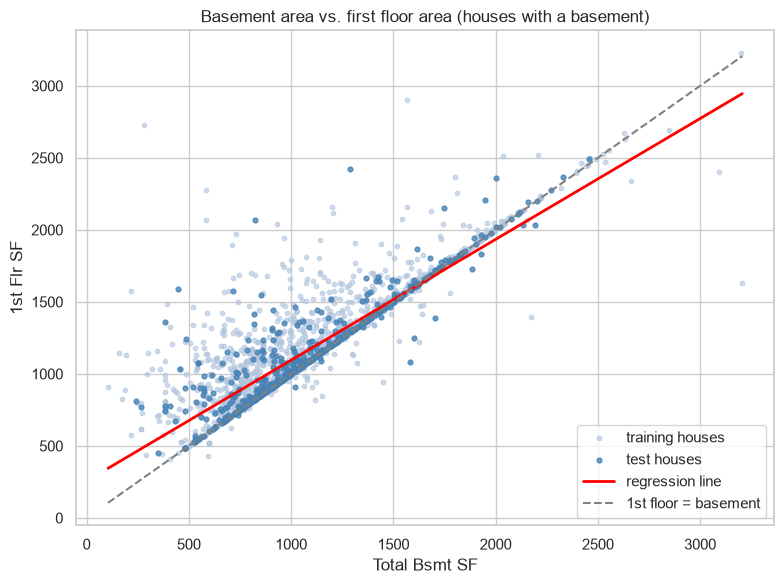

In [36]:
bsmt = clean_df[clean_df["Total Bsmt SF"] > 0]
print("houses with a basement:", len(bsmt))
print("r, all houses:", round(clean_df["Total Bsmt SF"].corr(clean_df["1st Flr SF"]), 2))
print("r, only houses with a basement:", round(bsmt["Total Bsmt SF"].corr(bsmt["1st Flr SF"]), 2))

Xb = bsmt[["Total Bsmt SF"]]
yb = bsmt["1st Flr SF"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, random_state=42)

bsmt_model = LinearRegression()
bsmt_model.fit(Xb_train, yb_train)
yb_pred = bsmt_model.predict(Xb_test)

print("Coefficient:", round(bsmt_model.coef_[0], 2))
print("Intercept:", round(bsmt_model.intercept_, 2))
print("Root mean squared error:", round(mean_squared_error(yb_test, yb_pred) ** 0.5))
print("R^2 on test data:", round(r2_score(yb_test, yb_pred), 2))

line = pd.DataFrame({"Total Bsmt SF": np.linspace(Xb["Total Bsmt SF"].min(), Xb["Total Bsmt SF"].max(), 100)})

plt.figure(figsize=(8, 6))
plt.scatter(Xb_train, yb_train, color="lightsteelblue", s=10, alpha=0.6, label="training houses")
plt.scatter(Xb_test, yb_test, color="steelblue", s=12, alpha=0.8, label="test houses")
plt.plot(line["Total Bsmt SF"], bsmt_model.predict(line), color="red", linewidth=2, label="regression line")
plt.plot(line["Total Bsmt SF"], line["Total Bsmt SF"], color="gray", linestyle="--",
         label="1st floor = basement")
plt.xlabel("Total Bsmt SF")
plt.ylabel("1st Flr SF")
plt.title("Basement area vs. first floor area (houses with a basement)")
plt.legend()
plt.tight_layout()
plt.show()

**What the plot shows:** without the houses that have no basement, the correlation goes up from 0.79 to 0.88. The regression line is `1st Flr SF ≈ 0.84 × Total Bsmt SF + 256`. On the test data R² = 0.82, and the typical error (RMSE) is about 154 sq ft.

The gray dashed line shows "first floor = basement". Many points lie exactly on it, and almost all the others are above it: very few houses have a basement that is bigger than the first floor. That's why the red line lies above the dashed one for basements up to about 1600 sq ft: the houses with a bigger first floor pull it up.

**Real vs. predicted** for five test houses, and predictions for some basement sizes we chose:

In [37]:
compare_b = Xb_test.copy()
compare_b["real 1st Flr SF"] = yb_test
compare_b["predicted"] = yb_pred.round()
compare_b["difference"] = compare_b["predicted"] - compare_b["real 1st Flr SF"]
print(compare_b.head(5))

new_basements = pd.DataFrame({"Total Bsmt SF": [500, 1000, 1500, 2000]})
new_basements["predicted 1st Flr SF"] = bsmt_model.predict(new_basements).round()
print(new_basements)

      Total Bsmt SF  real 1st Flr SF  predicted  difference
1624         1237.0             1253     1294.0        41.0
331           546.0              546      714.0       168.0
2186         1195.0             1195     1259.0        64.0
2582         1050.0             1050     1137.0        87.0
2239          961.0             1077     1063.0       -14.0
   Total Bsmt SF  predicted 1st Flr SF
0            500                 676.0
1           1000                1095.0
2           1500                1515.0
3           2000                1934.0


For the test houses where the first floor has exactly the size of the basement (546, 1050 and 1195 sq ft), the model predicts too much, by 64–168 sq ft. It predicts the average, and the average is pulled up by the houses with a bigger first floor. For the chosen sizes the predictions make sense: a 500 sq ft basement gives about 676 sq ft of first floor, 1500 sq ft gives about 1515 sq ft (almost the same) and 2000 sq ft gives 1934 sq ft. The model is most reliable between about 500 and 2000 sq ft, where most of the data is. Above 2500 sq ft there are only a few houses.

**Why do so many points lie above the line?** We compare the two areas for each house style:

In [38]:
diff = bsmt["1st Flr SF"] - bsmt["Total Bsmt SF"]
by_style = pd.DataFrame({"same size": diff == 0, "1st floor bigger": diff > 0, "basement bigger": diff < 0})
by_style = by_style.groupby(bsmt["House Style"]).mean().round(2)
by_style["houses"] = bsmt["House Style"].value_counts()
print("all houses with a basement:", (diff == 0).mean().round(2), "same size,",
      (diff > 0).mean().round(2), "1st floor bigger,", (diff < 0).mean().round(2), "basement bigger")
print(by_style.sort_values("houses", ascending=False))

all houses with a basement: 0.52 same size, 0.45 1st floor bigger, 0.03 basement bigger
             same size  1st floor bigger  basement bigger  houses
House Style                                                      
1Story            0.61              0.36             0.03    1420
2Story            0.51              0.46             0.03     861
1.5Fin            0.41              0.55             0.04     306
SLvl              0.10              0.88             0.02     127
SFoyer            0.33              0.67             0.00      82
2.5Unf            0.42              0.54             0.04      24
1.5Unf            0.37              0.63             0.00      19
2.5Fin            0.12              0.88             0.00       8


In 52% of the houses with a basement, the basement and the first floor have exactly the same size. In 45% the first floor is bigger, and only in 3% the basement is bigger. The first floor is bigger when the basement only covers part of the house. This is most common in split-level houses (`SLvl` 88%, `SFoyer` 67%), which are built on several levels. In one-story houses (`1Story`) the two areas are exactly equal 61% of the time.

**Real or spurious correlation?** We think it is real, because it comes from how houses are built: the first floor stands on the basement. Both areas also grow with the overall size of the house, but so many exactly equal areas can only come from the construction. Compare this with `Order` and `Yr Sold` (r = −0.98, section 2): that correlation only exists because the file is sorted by sale year. If we shuffled the rows it would disappear, so it is spurious and says nothing about the houses.

**What this means for lab 2:** `Total Bsmt SF` and `1st Flr SF` carry a lot of the same information (r = 0.88), so we wouldn't put both into a linear model without thinking about it. A straight line also isn't the perfect shape here. The real rule is closer to "the first floor is at least as big as the basement, and often exactly the same size".